# 4DEnVarOcn ocean analysis check: May-1 initial states vs observations

The May-start hindcasts of **E3SMv3-4DEnVarOcn** lose skill in 1990–1995 while E3SMv3-Reanalysis does not (`fair_4DEnVarOcn_acc_5yr_blocks.ipynb`), and already the first forecast month's Niño3.4 departs from observations in those years. This notebook checks the **initial conditions themselves**: the MPAS-Ocean restart (`mpaso.rst`) of every May-1 start, i.e. the ocean state each hindcast begins from.

**Question.** Does the 4DEnVar ocean analysis move closer to the observations after its 1980s spin-up, as expected, or does it drift away in the 1990s?

**Experiments** (restarts under `v3.LR.S2D.ENSINT/`): 4DEnVarOcn (full-field DA, the hindcast experiment), 4DEnVarOcn.AnomalyDA (anomaly DA, for comparison), BruteForce (the initial states of E3SMv3-Reanalysis) and JRA55-FOSIRL (forced ocean–sea-ice run). **Observations:** HadISST2 SST; the May-1 state is taken as the mean of the April and May monthly means.

**Method.** From each restart: the top-level temperature (SST) and the layer-thickness-weighted mean temperature of the upper ~300 m (T300), averaged onto a 2° grid (cell-area weighted; ice-shelf cavities excluded). Anomalies are taken against each source's own 1980–1995 mean of the May-1 states (the hindcast climatology period), so a constant model bias does not count as error; the absolute bias is shown separately to reveal drift. The extracted fields are cached (fixed file name) and rebuilt only when missing or when `REBUILD = True`.

**Diagnostics.**
1. Niño3.4 May-1 SST anomaly by year, all experiments and HadISST.
2. Per-year SST anomaly pattern correlation and RMSE vs HadISST (tropics and 60°S–60°N): the direct test of "closer to reality over time".
3. Absolute drift: area-mean SST bias vs HadISST and area-mean T300 by year (no subsurface observations; compare across experiments).
4. Maps of the RMS SST anomaly error per 5-year block.
5. Equatorial Pacific T300 anomaly (year × longitude): the subsurface ENSO state each hindcast starts from; FOSIRL serves as the reference without subsurface observations.

Each panel rests on one state per year, so single years are noisy; look for systematic changes between periods.


In [1]:
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from esp_lab import env_paths
from esp_lab.leadtime_plot_utils import add_lead_badge, style_global_map_axis
from esp_lab.utils import mapplot_utils as maps

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
RESTART_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT")
EXPERIMENTS = {   # restart folder, label, colour
    "4DEnVarOcn":           dict(folder="4DEnVarOcn",           label="4DEnVarOcn (full DA)",   color="tab:orange"),
    "4DEnVarOcn-AnomalyDA": dict(folder="4DEnVarOcn.AnomalyDA", label="4DEnVarOcn (anomaly DA)", color="tab:purple"),
    "Reanalysis":           dict(folder="BruteForce",           label="Reanalysis (BruteForce)", color="tab:blue"),
    "FOSIRL":               dict(folder="JRA55-FOSIRL",         label="JRA55-FOSIRL",            color="black"),
}
FOCUS = "4DEnVarOcn"
YEARS = list(range(1980, 1999))            # May-1 starts (4DEnVarOcn restarts end in 1998)
CLIMATOLOGY_YEARS = (1980, 1995)          # anomalies against each source's mean of these May-1 states
BLOCKS = [(1980, 1984), (1985, 1989), (1990, 1995)]
HIGHLIGHT = (1990, 1995)                  # shaded in the time-series figures
OBS_PATH = Path("/global/cfs/cdirs/e3sm/diagnostics/observations/Atm/time-series/HadISST2/tos_186901_202212.nc")
GRID_DEG = 2.0                            # target grid of the extracted fields
T300_DEPTH = 300.0                        # upper-ocean layer: levels with bottom depth <= this (m)
REGIONS = {"Tropics 30S-30N": (-30, 30), "60S-60N": (-60, 60)}
NINO34 = dict(lat=(-5, 5), lon=(190, 240))
EQ_PACIFIC = dict(lat=(-2, 2), lon=(120, 280))
REBUILD = False                           # True: re-extract the restarts even if the cache exists
N_THREADS = 8
FIGURE_SET = "4DEnVarOcn_analysis_check"
# ===== END CONFIGURATION BLOCK =====

DIAG_ROOT = env_paths.s2d_diag_root()
CACHE = DIAG_ROOT / "multimodel" / "initial_conditions" / f"ic_ocean_may01_sst_t300_{GRID_DEG:g}deg_{YEARS[0]}-{YEARS[-1]}.nc"
FIGURE_DIR = env_paths.figure_root() / FIGURE_SET
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CACHE.parent.mkdir(parents=True, exist_ok=True)
print(f"Cache: {CACHE}\nFigures: {FIGURE_DIR}")

Cache: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/initial_conditions/ic_ocean_may01_sst_t300_2deg_1980-1998.nc
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_analysis_check


## Extract SST and T300 from the May-1 restarts

Each restart is ~4 GB; only the upper levels of `temperature` and `layerThickness` are read. Missing restarts are reported and left as gaps.

In [3]:
NLAT, NLON = int(180 / GRID_DEG), int(360 / GRID_DEG)
LAT = -90 + GRID_DEG * (np.arange(NLAT) + 0.5)
LON = GRID_DEG * (np.arange(NLON) + 0.5)


def restart_path(folder, year):
    found = sorted((RESTART_ROOT / folder / f"{year}-05-01-00000").glob(f"*.mpaso.rst.{year}-05-01_00000.nc"))
    return found[0] if found else None


def to_grid(values, index, weight):
    """Area-weighted mean of cell values on the regular grid (NaN where no valid cell)."""
    ok = np.isfinite(values) & (weight > 0)
    num = np.bincount(index[ok], weights=(weight * values)[ok], minlength=NLAT * NLON)
    den = np.bincount(index[ok], weights=weight[ok], minlength=NLAT * NLON)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (num / den).reshape(NLAT, NLON)


def extract(folder, year):
    path = restart_path(folder, year)
    if path is None:
        return None
    with xr.open_dataset(path, decode_times=False) as ds:
        nlev = int((ds.refBottomDepth.values <= T300_DEPTH).sum())
        temp = ds.temperature.isel(Time=0, nVertLevels=slice(0, nlev)).values
        thick = ds.layerThickness.isel(Time=0, nVertLevels=slice(0, nlev)).values
        lat = np.rad2deg(ds.latCell.values)
        lon = np.rad2deg(ds.lonCell.values) % 360
        area = ds.areaCell.values
        max_level = ds.maxLevelCell.values
        open_ocean = np.ones_like(area, dtype=bool)
        if "landIceMask" in ds:
            open_ocean = ds.landIceMask.isel(Time=0).values == 0
    index = (np.clip(((lat + 90) // GRID_DEG).astype(int), 0, NLAT - 1) * NLON
             + (lon // GRID_DEG).astype(int) % NLON)
    active = np.arange(nlev)[None, :] < max_level[:, None]          # levels above the sea floor
    thick = np.where(active, thick, 0.0)
    t300 = np.where(thick.sum(1) > 0, (temp * thick).sum(1) / thick.sum(1), np.nan)
    weight = np.where(open_ocean, area, 0.0)
    return to_grid(temp[:, 0], index, weight), to_grid(t300, index, np.where(active.all(1), weight, 0.0))


def build_cache():
    jobs = [(key, info["folder"], year) for key, info in EXPERIMENTS.items() for year in YEARS]
    sst = np.full((len(EXPERIMENTS), len(YEARS), NLAT, NLON), np.nan)
    t300 = np.full_like(sst, np.nan)
    keys = list(EXPERIMENTS)
    with ThreadPoolExecutor(N_THREADS) as pool:
        results = list(pool.map(lambda job: extract(job[1], job[2]), jobs))
    for (key, folder, year), out in zip(jobs, results):
        if out is None:
            print(f"missing restart: {folder} {year}")
            continue
        sst[keys.index(key), YEARS.index(year)], t300[keys.index(key), YEARS.index(year)] = out
    coords = dict(experiment=keys, year=YEARS, lat=LAT, lon=LON)
    ds = xr.Dataset({"sst": (("experiment", "year", "lat", "lon"), sst),
                     "t300": (("experiment", "year", "lat", "lon"), t300)}, coords=coords)
    ds.sst.attrs.update(units="degC", long_name="May-1 top-level ocean temperature")
    ds.t300.attrs.update(units="degC", long_name=f"May-1 mean temperature of levels above {T300_DEPTH:g} m")
    ds.attrs.update(restart_root=str(RESTART_ROOT), folders=str({k: v["folder"] for k, v in EXPERIMENTS.items()}))
    tmp = CACHE.with_suffix(".tmp.nc")
    ds.to_netcdf(tmp)
    tmp.replace(CACHE)
    return ds


if REBUILD or not CACHE.exists():
    IC = build_cache()
else:
    IC = xr.open_dataset(CACHE).load()
    if list(IC.experiment.values) != list(EXPERIMENTS) or list(IC.year.values) != YEARS:
        IC = build_cache()
print(IC)

<xarray.Dataset> Size: 20MB
Dimensions:     (experiment: 4, year: 19, lat: 90, lon: 180)
Coordinates:
  * experiment  (experiment) <U20 320B '4DEnVarOcn' ... 'FOSIRL'
  * year        (year) int64 152B 1980 1981 1982 1983 ... 1995 1996 1997 1998
  * lat         (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 85.0 87.0 89.0
  * lon         (lon) float64 1kB 1.0 3.0 5.0 7.0 ... 353.0 355.0 357.0 359.0
Data variables:
    sst         (experiment, year, lat, lon) float64 10MB nan nan ... nan nan
    t300        (experiment, year, lat, lon) float64 10MB nan nan ... nan nan
Attributes:
    restart_root:  /global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT
    folders:       {'4DEnVarOcn': '4DEnVarOcn', '4DEnVarOcn-AnomalyDA': '4DEn...


## Observations and anomalies

HadISST2 on the same 2° grid; May-1 = mean of April and May. Anomalies against each source's own 1980–1995 mean.

In [4]:
hadisst = xr.open_dataset(OBS_PATH)["sst"]
hadisst = hadisst.where(hadisst > -1.5)                                    # drop sea-ice points
months = hadisst.sel(time=hadisst.time.dt.month.isin([4, 5]) & hadisst.time.dt.year.isin(YEARS))
obs_may1 = months.groupby("time.year").mean("time")
obs_may1 = obs_may1.coarsen(lat=int(GRID_DEG), lon=int(GRID_DEG), boundary="trim").mean()
obs_may1 = obs_may1.assign_coords(lat=LAT, lon=LON).load()

clim = slice(*CLIMATOLOGY_YEARS)
sst_anom = IC.sst - IC.sst.sel(year=clim).mean("year")
t300_anom = IC.t300 - IC.t300.sel(year=clim).mean("year")
obs_anom = obs_may1 - obs_may1.sel(year=clim).mean("year")
common = IC.sst.notnull().all(("experiment", "year")) & obs_may1.notnull().all("year")   # same cells everywhere
AREA = np.cos(np.deg2rad(IC.lat)) * xr.ones_like(IC.lon)


def area_mean(da, lat=(-90, 90), lon=(0, 360)):
    box = (da.lat >= lat[0]) & (da.lat <= lat[1]) & (da.lon >= lon[0]) & (da.lon <= lon[1])
    w = AREA.where(box & common).fillna(0)
    return da.weighted(w).mean(("lat", "lon"))


def pattern_scores(model, observed, lat):
    """Per-year centred pattern correlation and RMSE of anomalies over a latitude band."""
    w = AREA.where((IC.lat >= lat[0]) & (IC.lat <= lat[1]) & common).fillna(0)
    m = model - model.weighted(w).mean(("lat", "lon"))
    o = observed - observed.weighted(w).mean(("lat", "lon"))
    corr = (m * o).weighted(w).mean(("lat", "lon")) / np.sqrt(
        (m ** 2).weighted(w).mean(("lat", "lon")) * (o ** 2).weighted(w).mean(("lat", "lon")))
    rmse = np.sqrt(((model - observed) ** 2).weighted(w).mean(("lat", "lon")))
    return corr, rmse

In [5]:
def shade(ax):
    ax.axvspan(HIGHLIGHT[0] - 0.5, HIGHLIGHT[1] + 0.5, color="0.92", zorder=0)
    ax.grid(alpha=0.3)
    ax.set_xlim(YEARS[0] - 0.5, YEARS[-1] + 0.5)
    ax.set_xticks(YEARS[::2])


def save(fig, name):
    path = FIGURE_DIR / f"fig_{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(path)

## 1. Niño3.4 May-1 SST anomaly

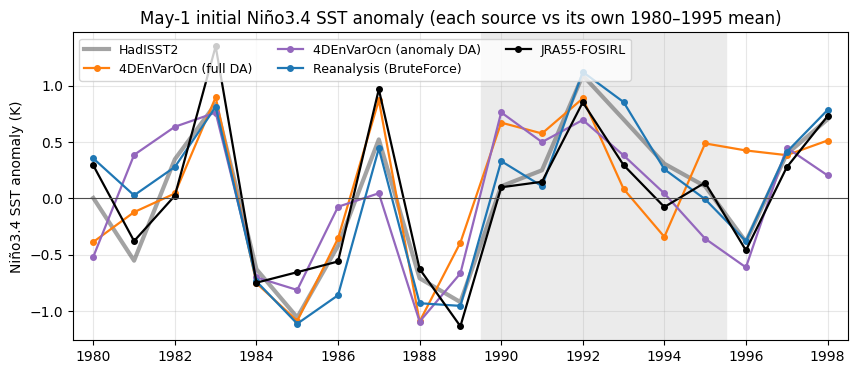

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_analysis_check/fig_ic_nino34_may01_anomaly.png


corr                                    rmse  \
period                  1980-1984 1985-1989 1990-1995 1996-1998 1980-1984   
experiment                                                                  
4DEnVarOcn (full DA)         0.86      0.91      0.21      0.46      0.30   
4DEnVarOcn (anomaly DA)      0.65      0.78      0.41      0.88      0.50   
Reanalysis (BruteForce)      0.87      0.96      0.95      1.00      0.31   
JRA55-FOSIRL                 0.92      0.94      0.88      0.99      0.31   

                                                       
period                  1985-1989 1990-1995 1996-1998  
experiment                                             
4DEnVarOcn (full DA)         0.33      0.48      0.48  
4DEnVarOcn (anomaly DA)      0.35      0.41      0.32  
Reanalysis (BruteForce)      0.22      0.14      0.05  
JRA55-FOSIRL                 0.29      0.25      0.08

In [6]:
nino = {key: area_mean(sst_anom.sel(experiment=key), **NINO34) for key in EXPERIMENTS}
nino_obs = area_mean(obs_anom, **NINO34)
fig, ax = plt.subplots(figsize=(10, 4))
shade(ax)
ax.plot(YEARS, nino_obs, color="0.4", lw=3, alpha=0.6, label="HadISST2")
for key, info in EXPERIMENTS.items():
    ax.plot(YEARS, nino[key], marker="o", ms=4, lw=1.6, color=info["color"], label=info["label"])
ax.axhline(0, color="0.3", lw=0.8)
ax.set_ylabel("Niño3.4 SST anomaly (K)")
ax.set_title("May-1 initial Niño3.4 SST anomaly (each source vs its own 1980–1995 mean)")
ax.legend(ncol=3, fontsize=9, loc="upper left")
save(fig, "ic_nino34_may01_anomaly")

rows = []
for key, info in EXPERIMENTS.items():
    for period in BLOCKS + [(1996, YEARS[-1])]:
        sel = slice(*period)
        a, b = nino[key].sel(year=sel), nino_obs.sel(year=sel)
        rows.append(dict(experiment=info["label"], period=f"{period[0]}-{period[1]}",
                         corr=float(np.corrcoef(a, b)[0, 1]), rmse=float(np.sqrt(((a - b) ** 2).mean()))))
pd.DataFrame(rows).pivot_table(index="experiment", columns="period", values=["corr", "rmse"], sort=False).round(2)

## 2. SST anomaly pattern vs HadISST by year

If the analysis converges after spin-up, the pattern correlation should rise and the RMSE fall over time.

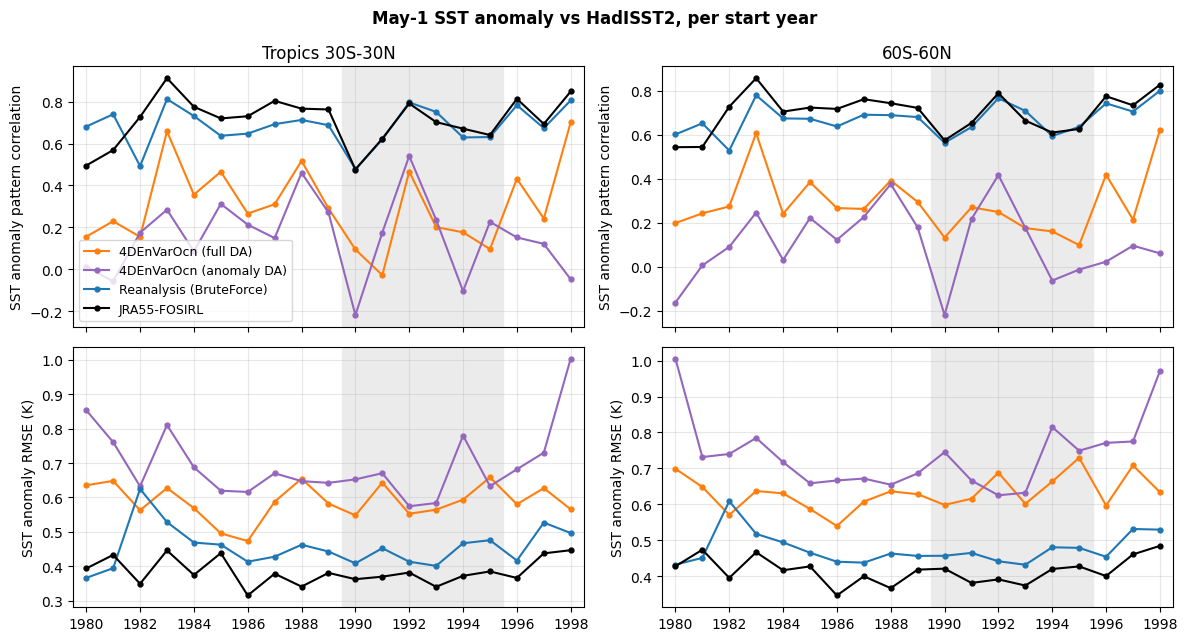

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_analysis_check/fig_ic_sst_anomaly_pattern_scores.png


corr                      \
period                                  1980-1984 1985-1989 1990-1995   
region          experiment                                              
Tropics 30S-30N 4DEnVarOcn (full DA)         0.31      0.37      0.17   
                4DEnVarOcn (anomaly DA)      0.10      0.28      0.14   
                Reanalysis (BruteForce)      0.69      0.68      0.65   
                JRA55-FOSIRL                 0.70      0.76      0.65   
60S-60N         4DEnVarOcn (full DA)         0.31      0.32      0.18   
                4DEnVarOcn (anomaly DA)      0.04      0.22      0.09   
                Reanalysis (BruteForce)      0.65      0.67      0.65   
                JRA55-FOSIRL                 0.67      0.73      0.65   

                                                       rmse            \
period                                  1996-1998 1980-1984 1985-1989   
region          experiment                                              
Tropics 30S-30N 4DEnVarOcn (full DA)         0.46      0.61      0.56   
                4DEnVarOcn (anomaly DA)      0.08      0.75      0.64   
                Reanalysis (BruteForce)      0.75      0.48      0.44   
                JRA55-FOSIRL                 0.78      0.40      0.37   
60S-60N         4DEnVarOcn (full DA)         0.42      0.64      0.60   
                4DEnVarOcn (anomaly DA)      0.06      0.80      0.67   
                Reanalysis (BruteForce)      0.75      0.50      0.45   
                JRA55-FOSIRL                 0.78      0.44      0.39   

                                                             
period                                  1990-1995 1996-1998  
region          experiment                                   
Tropics 30S-30N 4DEnVarOcn (full DA)         0.59      0.59  
                4DEnVarOcn (anomaly DA)      0.65      0.81  
                Reanalysis (BruteForce)      0.44      0.48  
                JRA55-FOSIRL                 0.37      0.42  
60S-60N         4DEnVarOcn (full DA)         0.65      0.65  
                4DEnVarOcn (anomaly DA)      0.71      0.84  
                Reanalysis (BruteForce)      0.46      0.51  
                JRA55-FOSIRL                 0.40      0.45

In [7]:
scores = {(key, region): pattern_scores(sst_anom.sel(experiment=key), obs_anom, lat)
          for key in EXPERIMENTS for region, lat in REGIONS.items()}
fig, axes = plt.subplots(2, len(REGIONS), figsize=(6 * len(REGIONS), 6.5), sharex=True)
for c, region in enumerate(REGIONS):
    for r, (metric, label) in enumerate((("corr", "pattern correlation"), ("rmse", "RMSE (K)"))):
        ax = axes[r, c]
        shade(ax)
        for key, info in EXPERIMENTS.items():
            ax.plot(YEARS, scores[(key, region)][r], marker="o", ms=3.5, lw=1.5, color=info["color"], label=info["label"])
        ax.set_ylabel(f"SST anomaly {label}")
        if r == 0:
            ax.set_title(region)
axes[0, 0].legend(fontsize=9)
fig.suptitle("May-1 SST anomaly vs HadISST2, per start year", fontweight="bold")
fig.tight_layout()
save(fig, "ic_sst_anomaly_pattern_scores")

rows = []
for (key, region), (corr, rmse) in scores.items():
    for period in BLOCKS + [(1996, YEARS[-1])]:
        sel = slice(*period)
        rows.append(dict(experiment=EXPERIMENTS[key]["label"], region=region, period=f"{period[0]}-{period[1]}",
                         corr=float(corr.sel(year=sel).mean()), rmse=float(rmse.sel(year=sel).mean())))
pd.DataFrame(rows).pivot_table(index=["region", "experiment"], columns="period", values=["corr", "rmse"], sort=False).round(2)

## 3. Absolute drift

Raw values, no anomalies: the area-mean SST bias against HadISST (60°S–60°N) and the area-mean upper-300 m temperature. A drifting analysis shows up as a trend that the other experiments do not have.

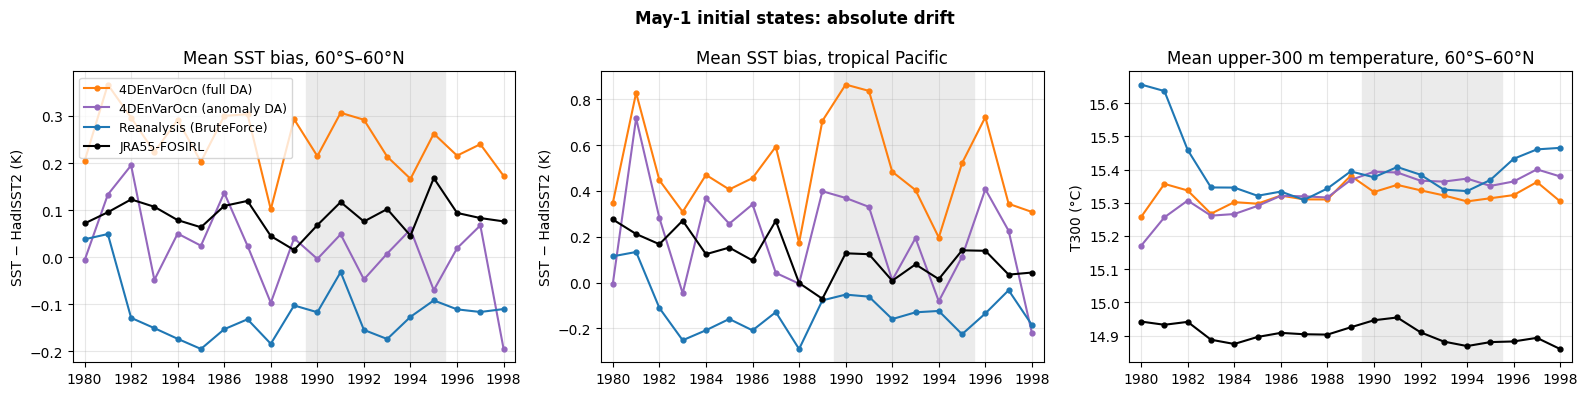

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_analysis_check/fig_ic_absolute_drift.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax in axes:
    shade(ax)
for key, info in EXPERIMENTS.items():
    sst = IC.sst.sel(experiment=key)
    axes[0].plot(YEARS, area_mean(sst - obs_may1, lat=(-60, 60)), marker="o", ms=3.5, color=info["color"], label=info["label"])
    axes[1].plot(YEARS, area_mean(sst - obs_may1, lat=(-15, 15), lon=(120, 280)), marker="o", ms=3.5, color=info["color"])
    axes[2].plot(YEARS, area_mean(IC.t300.sel(experiment=key), lat=(-60, 60)), marker="o", ms=3.5, color=info["color"])
axes[0].set_ylabel("SST − HadISST2 (K)"); axes[0].set_title("Mean SST bias, 60°S–60°N")
axes[1].set_ylabel("SST − HadISST2 (K)"); axes[1].set_title("Mean SST bias, tropical Pacific")
axes[2].set_ylabel("T300 (°C)"); axes[2].set_title("Mean upper-300 m temperature, 60°S–60°N")
axes[0].legend(fontsize=9)
fig.suptitle("May-1 initial states: absolute drift", fontweight="bold")
fig.tight_layout()
save(fig, "ic_absolute_drift")

## 4. RMS SST anomaly error per block

RMS over the start years of each block of (initial SST anomaly − HadISST2 anomaly); the panel label is the 60°S–60°N area mean.

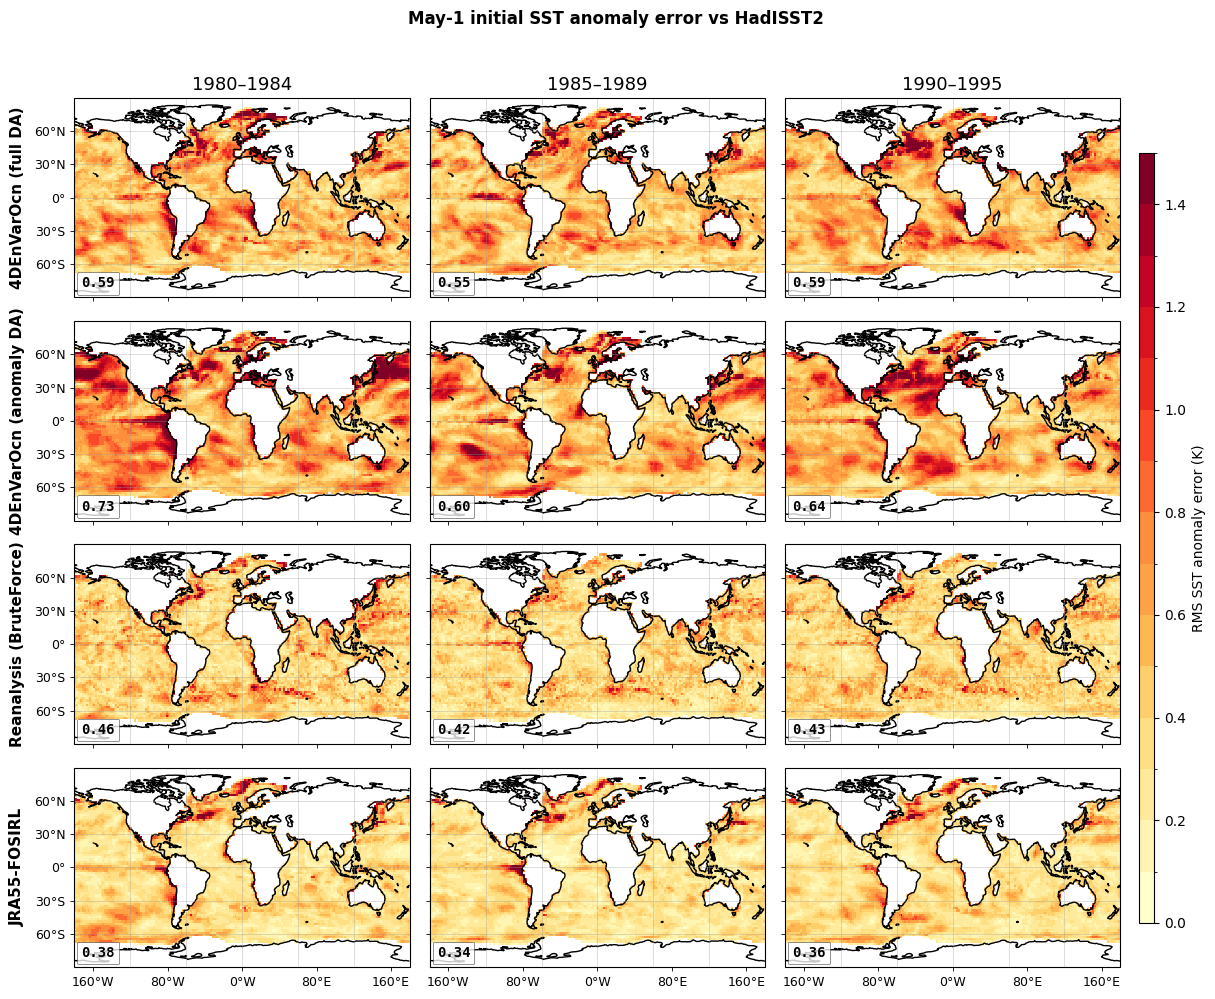

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_analysis_check/fig_ic_sst_anomaly_error_maps.png


In [9]:
MAP_STYLE = dict(lon_ticks=[-160, -80, 0, 80, 160], lat_ticks=[-60, -30, 0, 30, 60],
                 tick_length=3, tick_width=0.6, grid_linewidth=0.4, grid_color="0.6", grid_alpha=0.6)
rows_ = [k for k in EXPERIMENTS if k != "FOSIRL"] + ["FOSIRL"]
fig = plt.figure(figsize=(4.2 * len(BLOCKS), 2.5 * len(rows_) + 1))
for r, key in enumerate(rows_):
    for c, period in enumerate(BLOCKS):
        err = np.sqrt(((sst_anom.sel(experiment=key) - obs_anom).sel(year=slice(*period)) ** 2).mean("year"))
        err = err.where(common)
        ax, mappable = maps.map_pcolor_global_subplot(
            fig, err, err.lon, err.lat, 0.1, 0.0, 1.5, f"{period[0]}–{period[1]}" if r == 0 else "",
            len(rows_), len(BLOCKS), r * len(BLOCKS) + c + 1, ccrs.PlateCarree(), cmap="YlOrRd", fontsize=13)
        style_global_map_axis(ax, row=r, column=c, nrows=len(rows_), label_size=9, style=MAP_STYLE)
        add_lead_badge(ax, f"{float(area_mean(err, lat=(-60, 60))):.2f}", font_size=10)
        if c == 0:
            ax.text(-0.17, 0.5, EXPERIMENTS[key]["label"], transform=ax.transAxes, rotation=90,
                    ha="center", va="center", fontsize=11, fontweight="bold")
fig.subplots_adjust(left=0.07, right=0.9, wspace=0.06, hspace=0.12, top=0.9)
cax = fig.add_axes([0.915, 0.15, 0.012, 0.7])
fig.colorbar(mappable, cax=cax).set_label("RMS SST anomaly error (K)")
fig.suptitle("May-1 initial SST anomaly error vs HadISST2", fontweight="bold")
save(fig, "ic_sst_anomaly_error_maps")

## 5. Equatorial Pacific upper-ocean state

May-1 T300 anomaly averaged over 2°S–2°N, by start year and longitude. There are no subsurface observations here; FOSIRL (forced by JRA55) is the reference. The difference to FOSIRL is summarised in the table.

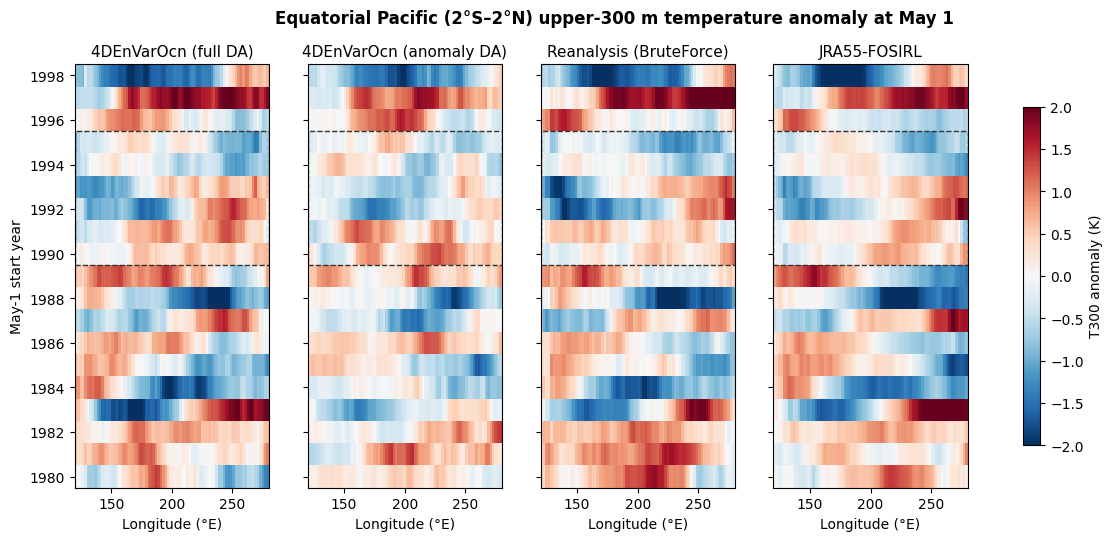

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_analysis_check/fig_ic_eq_pacific_t300_hovmoller.png


corr                                    rmse  \
period                  1980-1984 1985-1989 1990-1995 1996-1998 1980-1984   
experiment                                                                  
4DEnVarOcn (full DA)         0.84      0.77      0.79      0.90      0.53   
4DEnVarOcn (anomaly DA)      0.46      0.37      0.49      0.67      0.84   
Reanalysis (BruteForce)      0.82      0.89      0.89      0.93      0.58   

                                                       
period                  1985-1989 1990-1995 1996-1998  
experiment                                             
4DEnVarOcn (full DA)         0.64      0.43      0.53  
4DEnVarOcn (anomaly DA)      0.96      0.62      0.87  
Reanalysis (BruteForce)      0.43      0.36      0.48

In [10]:
eq = t300_anom.sel(lat=slice(*EQ_PACIFIC["lat"]), lon=slice(*EQ_PACIFIC["lon"]))
eq = eq.weighted(np.cos(np.deg2rad(eq.lat))).mean("lat")
fig, axes = plt.subplots(1, len(EXPERIMENTS), figsize=(3.6 * len(EXPERIMENTS), 5.5), sharey=True)
for ax, (key, info) in zip(axes, EXPERIMENTS.items()):
    pc = ax.pcolormesh(eq.lon, eq.year, eq.sel(experiment=key), cmap="RdBu_r", vmin=-2, vmax=2, shading="nearest")
    ax.axhspan(HIGHLIGHT[0] - 0.5, HIGHLIGHT[1] + 0.5, fill=False, edgecolor="0.2", lw=1, ls="--")
    ax.set_title(info["label"], fontsize=11)
    ax.set_xlabel("Longitude (°E)")
axes[0].set_ylabel("May-1 start year")
axes[0].set_yticks(YEARS[::2])
fig.colorbar(pc, ax=axes, shrink=0.8, label="T300 anomaly (K)")
fig.suptitle("Equatorial Pacific (2°S–2°N) upper-300 m temperature anomaly at May 1", fontweight="bold")
save(fig, "ic_eq_pacific_t300_hovmoller")

rows = []
ref = eq.sel(experiment="FOSIRL")
for key, info in EXPERIMENTS.items():
    if key == "FOSIRL":
        continue
    for period in BLOCKS + [(1996, YEARS[-1])]:
        a, b = eq.sel(experiment=key, year=slice(*period)), ref.sel(year=slice(*period))
        rows.append(dict(experiment=info["label"], period=f"{period[0]}-{period[1]}",
                         corr=float(xr.corr(a, b)), rmse=float(np.sqrt(((a - b) ** 2).mean()))))
pd.DataFrame(rows).pivot_table(index="experiment", columns="period", values=["corr", "rmse"], sort=False).round(2)